In [1]:
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")
# Permite importar el paquete `proyecto` sin instalarlo: el código vive en src/
sys.path.insert(0, str(Path.cwd().resolve().parent / "src"))

# 05 · Torneo de modelos

El torneo no busca un campeón: busca **uno o dos finalistas** para optimizar, con evidencia y **sin tocar la prueba**.
Tres reglas:

1. **Mismos datos, mismas variables y mismos pliegues para todos** (los del notebook 04, por asociado).
2. **Un punto de referencia** que cualquier modelo serio debe superar.
3. **Mirar la variación entre pliegues**, no solo el promedio: una diferencia menor que esa variación no es un hallazgo.

| Candidato | Por qué está |
|---|---|
| Baseline (clase mayoritaria) | Referencia: lo que se logra sin aprender nada |
| Regresión Logística | Interpretable: cada variable tiene un coeficiente con signo que un comité puede auditar |
| Árbol de Decisión | Reglas legibles; un solo árbol |
| Random Forest | Muchos árboles **independientes** promediados (bagging): robusto |
| K-Vecinos | Decide por parecido con los asociados más cercanos; sin supuestos de forma |
| Gradient Boosting | Árboles **en secuencia**, cada uno corrige los errores del anterior |

Son los modelos del README del equipo, con los **parámetros por defecto de scikit-learn** (sin optimizar: eso se hace
después, solo con los finalistas). Como pidió el profesor, se arranca por lo más simple e interpretable (la regresión
logística) y se sube en complejidad solo si hace falta más poder predictivo; el torneo dice cuánto se gana al subir.

**El código vive en `src/proyecto/models/train.py`**, construido sobre el del ejemplo del curso, con las tres piezas de
la clase 3. Este notebook solo lo llama:

| Pieza | Función | Qué hace |
|---|---|---|
| 1 · Candidatos | `candidates()`, `build_pipeline()` | Los seis modelos y el pipeline común (variables + preprocesamiento + modelo) |
| 2 · Métricas | `fold_metrics()` | Negocio (beneficio neto con dos reglas de decisión) y técnicas (ordenamiento, clasificación y calidad de probabilidades) |
| 3 · Validación cruzada | `evaluate_folds()`, `run_tournament()` | Los mismos 5 pliegues para todos; una fila por pliegue |
| Lectura contra el ruido | `summarize()`, `paired_comparison()` | Media ± desviación entre pliegues y comparación pliegue a pliegue |

### Dos decisiones de diseño, y por qué

**El baseline no compite: sirve de referencia.** `DummyClassifier(strategy="most_frequent")` responde siempre "no
radica", sin mirar ninguna variable. No es un predictor aleatorio —es un predictor constante— y su función es dar la
medida de cuánto aporta modelar frente a no modelar. Sin él, un 0,79 de exactitud parecería un buen resultado.

**Ningún modelo recibe tratamiento del desbalance.** Ni `class_weight`, ni remuestreo. La razón es que ese ajuste no
mejora la capacidad de un modelo: mueve su punto de operación, favoreciendo el recall a costa de la precisión. Si unos
modelos lo tuvieran y otros no, el torneo compararía puntos de operación distintos en lugar de modelos. El desbalance
se aborda después, de forma explícita y solo para el modelo ya elegido (elección del umbral, notebooks 06 y 07).

### Qué vamos a medir, y por qué

La decisión que alimenta este modelo es a qué asociados dirigir una acción de retención antes de que radiquen. Los dos
errores posibles cuestan cosas muy distintas:

| Resultado | Qué significa | Qué cuesta |
|---|---|---|
| **Verdadero positivo (VP)** | iba a radicar y el modelo lo detecta | nada: es el acierto que buscamos |
| **Falso positivo (FP)** | no iba a radicar y el modelo lo marca | una comunicación, un souvenir, una llamada |
| **Falso negativo (FN)** | iba a radicar y el modelo no lo ve | **el retiro total de los aportes de ese asociado** |
| **Verdadero negativo (VN)** | no iba a radicar y el modelo no lo marca | nada |

**El objetivo es maximizar los verdaderos positivos**, aun a costa de aceptar falsos positivos. Un falso positivo
cuesta el precio de una acción de fidelización —que además refuerza el vínculo asociativo, de modo que ni siquiera es
puro desperdicio—. Un falso negativo cuesta un asociado y el saldo completo de sus aportes. **La asimetría es grande**:
con los supuestos del notebook 01, dejar pasar a quien radica cuesta 6,8 veces más que contactar a quien no.

De ahí se desprenden las métricas:

| Métrica | Qué responde | Por qué se incluye |
|---|---|---|
| **AUC-ROC** | ¿ordena bien a los asociados, de más a menos riesgo? | resume la capacidad del modelo sin depender del umbral; sirve para comparar en el torneo |
| **Recall de la clase 1** | de quienes radicaron, ¿a cuántos detectó? | mide la **oportunidad perdida**: es la métrica alineada con el costo real |
| **Precisión de la clase 1** | de los marcados, ¿cuántos iban a radicar? | mide el **esfuerzo desperdiciado**; se reporta para dimensionar el costo operativo |
| **F1 de la clase 1** | equilibrio entre las dos | resumen, siempre leído junto a las dos anteriores |
| **Promedio de precisión (AP o PR-AUC)** | área bajo la curva precisión–recall | más informativa que el AUC cuando la clase positiva es minoritaria |
| **Beneficio neto por cada 1.000 asociados** | ¿cuánto deja la campaña guiada por el modelo? | la métrica de negocio del notebook 01 (regla de valor esperado, supuestos a la vista); se calcula también con el umbral 0,5 para medir cuánto aporta la regla |
| **Puntaje de Brier y log loss** | ¿las probabilidades son creíbles? | la regla de valor esperado usa la probabilidad como número |
| **Exactitud balanceada, recall y precisión de la clase 0, F1 macro** | ¿trata bien a las dos clases? | las técnicas que pide la guía del curso; la exactitud balanceada promedia el recall de las dos clases y no premia a quien ignora a una |

**La exactitud (*accuracy*) se excluye deliberadamente.** Con una clase mayoritaria del 79 %, es la métrica que premia
al modelo que nunca detecta a nadie. La exactitud **balanceada** no tiene ese problema: el baseline queda en 0,5.

Recall, precisión, F1 y exactitud balanceada se reportan en el **umbral por defecto (0,5)**, que no es el punto de
operación final: dicen cómo decide cada modelo "de fábrica". AUC y PR-AUC no dependen del umbral.

> **Y una regla que aplicamos en todo el notebook:** cada vez que comparemos dos números obtenidos por validación
> cruzada, diremos si la diferencia es mayor o menor que la **variación esperada entre pliegues**. Una diferencia más
> pequeña que esa variación no es un hallazgo.

## 0. Datos, pliegues y variables

In [2]:
import json
import time

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from proyecto.config import CONTACT_COST, PROCESSED_DIR, RANDOM_STATE, REPORTS_DIR, RETENTION_RATE, TARGET
from proyecto.data.split import make_folds
from proyecto.features.engineering import SUSPECT_COLUMNS, SUSPECT_ENGINEERED
from proyecto.models.business import campaign_value
from proyecto.models.train import (build_pipeline, candidates, evaluate_folds, paired_comparison, run_tournament,
                                   summarize)
from proyecto.viz import (ALERT, CHURN, LIGHT, NEUTRAL, STAY, SUBTEXT, TEXT, decimal_axis, fmt_num, fmt_pct, pct_axis,
                          set_style, table, titled)

set_style()
pd.set_option("display.width", 170)

train = joblib.load(PROCESSED_DIR / "train.joblib")
folds = joblib.load(PROCESSED_DIR / "folds.joblib")
same = all((a == c).all() and (b == d).all() for (a, b), (c, d) in zip(folds, make_folds(train, seed=RANDOM_STATE)))
assert same, "los pliegues guardados no coinciden con los del notebook 04"
selection = json.loads((REPORTS_DIR / "04_seleccion_variables.json").read_text(encoding="utf-8"))
columns = selection["columns"]

print(f"Entrenamiento: {fmt_num(len(train))} asociados · 5 pliegues por asociado (los del notebook 04) · prueba cerrada")
print(f"Variables (decididas en el notebook 04): {len(columns)}")
print(f"Tasa de radicación: {fmt_pct(train[TARGET].mean(), 2)}")

Entrenamiento: 155.258 asociados · 5 pliegues por asociado (los del notebook 04) · prueba cerrada
Variables (decididas en el notebook 04): 27
Tasa de radicación: 20,92 %


## 1. Correr el torneo

Cada candidato se entrena y se valida en los 5 pliegues, con **el mismo pipeline** (variables nuevas, imputación,
logaritmo y escalado). Los modelos de árboles no necesitan el logaritmo ni el escalado, pero tampoco les afectan
(son transformaciones que no cambian el orden de los valores): así nadie compite en mejores condiciones. Se guarda
**cada pliegue** y la probabilidad fuera de pliegue de cada asociado.

In [3]:
folds_by_model, oof = run_tournament(candidates(), columns, train, folds)
joblib.dump(oof, PROCESSED_DIR / "05_oof_probabilidades.joblib")
pd.concat(folds_by_model).to_csv(REPORTS_DIR / "05_torneo_pliegues.csv")

Baseline (clase mayoritaria)   listo en     3 s


Regresión Logística            listo en     5 s


Árbol de Decisión              listo en    15 s


Random Forest                  listo en    90 s


K-Vecinos                      listo en    94 s


Gradient Boosting              listo en   236 s


## 2. ¿Quién ordena mejor el riesgo?

Media ± desviación entre pliegues. La tabla se ordena por AUC.

In [4]:
full = summarize(folds_by_model, ["AUC", "PR-AUC", "recall", "precisión", "F1", "exactitud balanceada",
                                   "recall clase 0", "precisión clase 0", "F1 macro", "Brier", "log loss",
                                   "segundos de ajuste", "segundos de predicción"]).sort_values("AUC", ascending=False)
full.to_csv(REPORTS_DIR / "05_torneo_tabla.csv")
summary = full[["AUC", "± AUC", "PR-AUC", "± PR-AUC", "recall", "precisión", "F1", "Brier", "segundos de ajuste",
                "segundos de predicción"]]
display(table(summary, decimals=4, col_decimals={"segundos de ajuste": 1, "segundos de predicción": 1}))

,AUC,± AUC,PR-AUC,± PR-AUC,recall,precisión,F1,Brier,segundos de ajuste,segundos de predicción
Random Forest,"0,8951","0,0017","0,7015","0,0064","0,5056","0,7429","0,6016","0,1005","17,3","0,5"
Gradient Boosting,"0,8877","0,0015","0,6827","0,0069","0,4713","0,7254","0,5714","0,1044","46,9","0,1"
Regresión Logística,"0,8189","0,0020","0,5145","0,0047","0,2810","0,6146","0,3856","0,1291","1,0","0,1"
K-Vecinos,"0,7921","0,0015","0,4843","0,0018","0,4315","0,5769","0,4937","0,1348","0,7","17,9"
Árbol de Decisión,"0,6988","0,0031","0,3713","0,0031","0,5289","0,5158","0,5222","0,2024","3,0","0,1"
Baseline (clase mayoritaria),"0,5000","0,0000","0,2092","0,0000","0,0000","0,0000","0,0000","0,2092","0,5","0,1"


### 2.1 Las demás métricas técnicas (las dos clases)

Las que pide la guía del curso para ver si un modelo descuida alguna de las dos clases. Todas en el umbral 0,5, salvo el
log loss, que mide la calidad de las probabilidades (menor es mejor).

In [5]:
classes = full[["exactitud balanceada", "recall", "recall clase 0", "precisión", "precisión clase 0", "F1", "F1 macro",
                "log loss"]].rename(columns={"recall": "recall clase 1", "precisión": "precisión clase 1", "F1": "F1 clase 1"})
display(table(classes, decimals=4))

,exactitud balanceada,recall clase 1,recall clase 0,precisión clase 1,precisión clase 0,F1 clase 1,F1 macro,log loss
Random Forest,"0,7296","0,5056","0,9537","0,7429","0,8794","0,6016","0,7584","0,3247"
Gradient Boosting,"0,7121","0,4713","0,9528","0,7254","0,8720","0,5714","0,7410","0,3303"
Regresión Logística,"0,6172","0,2810","0,9534","0,6146","0,8337","0,3856","0,6376","0,3994"
K-Vecinos,"0,6739","0,4315","0,9163","0,5769","0,8590","0,4937","0,6902","0,7605"
Árbol de Decisión,"0,6988","0,5289","0,8687","0,5158","0,8746","0,5222","0,6969","2,7960"
Baseline (clase mayoritaria),"0,5000","0,0000","1,0000","0,0000","0,7908","0,0000","0,4416","2,8896"


**Lectura (las dos clases).**

- **Ningún modelo descuida a quienes no radican:** el recall de la clase 0 está entre 0,87 y 0,95. En el umbral 0,5 el
  problema está del otro lado: dejan escapar a muchos de quienes sí radican (recall de la clase 1 entre 0,28 y 0,53).
- **Exactitud balanceada y F1 macro ordenan igual a los tres primeros:** Random Forest (0,7296 y 0,7584), Gradient
  Boosting (0,7121 y 0,7410). El baseline queda en 0,5 de exactitud balanceada: esta métrica, a diferencia de la exactitud
  simple, no lo premia.
- **La Regresión Logística cae al último lugar entre los modelos en estas métricas** (exactitud balanceada 0,6172),
  porque sus probabilidades rara vez pasan de 0,5 y en ese umbral detecta solo al 28 % de quienes radican. No es falta
  de capacidad para ordenar (su AUC es el tercero): es su punto de operación de fábrica.
- **El log loss confirma al Brier:** Random Forest tiene las mejores probabilidades (0,3247). El Árbol de Decisión
  (2,7960) casi iguala al baseline (2,8896): cuando se equivoca, lo hace con total seguridad.

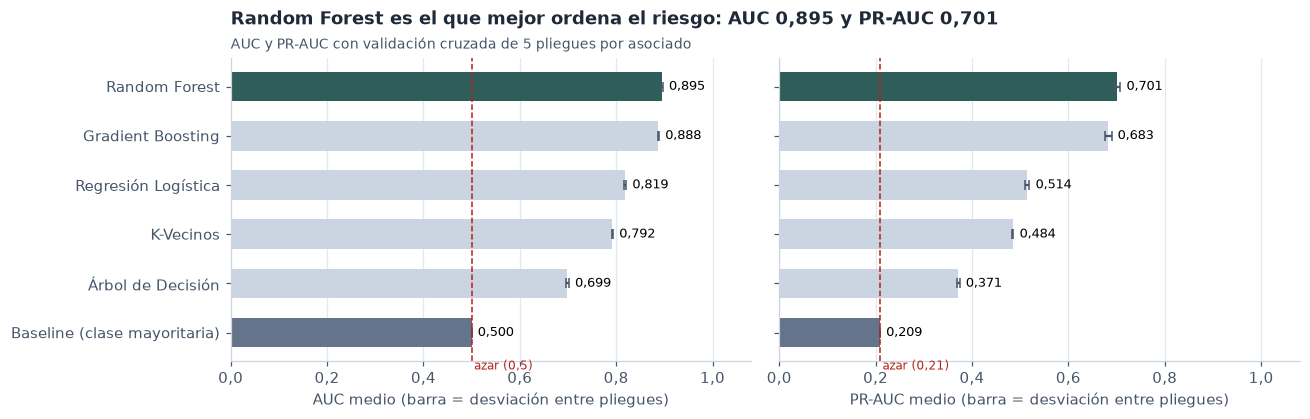

In [6]:
order = summary.index[::-1]
base_rate = train[TARGET].mean()
fig, axes = plt.subplots(1, 2, figsize=(12, 3.9), sharey=True)
for ax, metric, floor, floor_label in [(axes[0], "AUC", 0.5, "azar (0,5)"),
                                       (axes[1], "PR-AUC", base_rate, f"azar ({fmt_num(base_rate, 2)})")]:
    values = summary.loc[order, metric]
    errors = summary.loc[order, f"± {metric}"]
    colors = [NEUTRAL if n.startswith("Baseline") else (STAY if n == summary.index[0] else LIGHT) for n in order]
    bars = ax.barh(order, values, xerr=errors, color=colors, height=0.6, error_kw={"ecolor": SUBTEXT, "capsize": 3})
    ax.bar_label(bars, labels=[fmt_num(v, 3) for v in values], padding=4, fontsize=8.5)
    ax.axvline(floor, color=ALERT, ls="--", lw=1)
    ax.text(floor + 0.005, -0.75, floor_label, color=ALERT, fontsize=8)
    ax.set_xlim(0, 1.08); ax.grid(axis="y", visible=False); decimal_axis(ax, "x")
    ax.set_xlabel(f"{metric} medio (barra = desviación entre pliegues)")
best = summary.index[0]
titled(axes[0], f"{best} es el que mejor ordena el riesgo: AUC {fmt_num(summary.loc[best, 'AUC'], 3)} y "
                f"PR-AUC {fmt_num(summary.loc[best, 'PR-AUC'], 3)}",
       "AUC y PR-AUC con validación cruzada de 5 pliegues por asociado")
plt.tight_layout(); plt.show()

**Qué dice el torneo.**

- **Modelar aporta, y mucho.** El baseline queda en AUC 0,5 y PR-AUC 0,209, justo la tasa de radicación: no distingue a
  nadie. El líder lo supera por casi 0,40 de AUC, más de 200 veces su variación entre pliegues (cifra exacta en la
  sección 3).
- **Los dos ensambles de árboles encabezan**: Random Forest (AUC 0,8951, PR-AUC 0,7015) y Gradient Boosting (0,8877 y
  0,6827). La **Regresión Logística**, aun con las variables nuevas que la ayudaron en el notebook 04, queda en 0,8189 y
  0,5145; **K-Vecinos** en 0,7921 y 0,4843.
- **El Árbol de Decisión** queda último (0,6988 y 0,3713): con los parámetros por defecto crece sin límite de
  profundidad, memoriza el entrenamiento y sus probabilidades son solo 0 o 1 (su Brier, 0,2024, casi iguala al del
  baseline, 0,2092).
- **El PR-AUC agranda las diferencias** que el AUC sugiere: entre Random Forest y la logística la brecha es de 0,076 en
  AUC pero de 0,187 en PR-AUC. Con una clase positiva del 21 %, el PR-AUC describe mejor cuánto vale la lista de contacto.
- **En el umbral 0,5 el recall es bajo para todos** (Random Forest 0,506; logística 0,281): con clases desbalanceadas,
  ese umbral deja fuera a la mayoría de quienes radican. **No es el desempeño final** de ningún modelo, es el punto de
  operación de fábrica, que se elige después. El árbol tiene el recall más alto (0,529) solo porque sus probabilidades son
  0 o 1, no porque detecte mejor.
- **Tiempos** (varían un poco entre ejecuciones): Gradient Boosting es el más lento para entrenar (unos 50 s por pliegue)
  y K-Vecinos el más lento para predecir (casi 20 s por pliegue de 31.052 asociados).

## 3. ¿Las diferencias superan el ruido?

Primero contra el líder, con la variación entre pliegues del líder como ruido típico. Después, la comparación
**pareada** de los mejores: como todos se evaluaron en los mismos pliegues, se puede ver si uno gana en todos.

In [7]:
contenders = summary.drop(index=[n for n in summary.index if n.startswith("Baseline")])
leader = contenders.index[0]
vs_leader = pd.DataFrame({
    "AUC": contenders["AUC"],
    "diferencia con el líder": contenders.loc[leader, "AUC"] - contenders["AUC"],
    "ruido típico (± AUC del líder)": contenders.loc[leader, "± AUC"],
})
vs_leader["veces el ruido"] = vs_leader["diferencia con el líder"] / vs_leader["ruido típico (± AUC del líder)"]
vs_leader["¿supera el ruido?"] = np.where(vs_leader.index == leader, "— líder —",
                                          np.where(vs_leader["veces el ruido"] > 1, "sí", "no: empate"))
display(table(vs_leader, decimals=4, col_decimals={"veces el ruido": 1}))

baseline_name = [n for n in summary.index if n.startswith("Baseline")][0]
gap = summary.loc[leader, "AUC"] - summary.loc[baseline_name, "AUC"]
print(f"El líder ({leader}) supera al baseline por {fmt_num(gap, 4)} de AUC: "
      f"{fmt_num(gap / summary.loc[leader, '± AUC'], 0)} veces su variación entre pliegues.")

top = list(contenders.index[:3])
pairs = []
for i in range(len(top)):
    for j in range(i + 1, len(top)):
        for metric in ["AUC", "PR-AUC", "beneficio neto (por 1.000)"]:
            pairs.append({"mejor": top[i], "contra": top[j], "métrica": metric,
                          **paired_comparison(folds_by_model[top[i]][metric], folds_by_model[top[j]][metric])})
pairs = pd.DataFrame(pairs)
display(table(pairs.set_index(["mejor", "contra", "métrica"]), decimals=4, col_decimals={"diferencia / ruido": 1}))

,AUC,diferencia con el líder,ruido típico (± AUC del líder),veces el ruido,¿supera el ruido?
Random Forest,"0,8951","0,0000","0,0017","0,0",— líder —
Gradient Boosting,"0,8877","0,0075","0,0017","4,3",sí
Regresión Logística,"0,8189","0,0762","0,0017","44,1",sí
K-Vecinos,"0,7921","0,1030","0,0017","59,5",sí
Árbol de Decisión,"0,6988","0,1963","0,0017","113,5",sí


El líder (Random Forest) supera al baseline por 0,3951 de AUC: 228 veces su variación entre pliegues.


**Lectura contra el ruido.**

- **Todas las diferencias con el líder superan la variación entre pliegues.** La más pequeña, Random Forest frente a
  Gradient Boosting, es 4,3 veces el ruido típico del líder; la logística está a 44 veces y el árbol a más de 100.
- **En la comparación pareada, Random Forest le gana a Gradient Boosting en los 5 pliegues** en AUC y en PR-AUC
  (diferencia / ruido de 12,1 y 4,6): pequeña, pero consistente.
- **En beneficio neto, en cambio, empatan.** Random Forest gana en los 5 pliegues, pero por 0,045 millones por cada 1.000
  asociados, **0,8 veces el ruido**: con otra partición la diferencia podría desaparecer. Ordenan distinto, pero para la
  decisión de negocio valen lo mismo.
- **Los dos superan a la Regresión Logística en todo**, en los 5 pliegues y por muchas veces el ruido (también en
  beneficio neto: 7,2 y 9,1 veces).

## 4. ¿Cuánto vale cada modelo para el negocio?

Beneficio neto de la campaña guiada por cada modelo, con la regla de valor esperado del notebook 01 (contactar si
*probabilidad × 20 % × saldo de aportes > $30.000*), por cada 1.000 asociados de validación. Se compara con
**contactar a todos**, calculado en los mismos pliegues.

In [8]:
y = train[TARGET].to_numpy()
value = train["saldo_aportes"].to_numpy()
mass = []
for _, valid_idx in folds:
    result = campaign_value(y[valid_idx], np.ones(len(valid_idx)), value[valid_idx], CONTACT_COST, RETENTION_RATE)
    mass.append(result["beneficio_neto"] / len(valid_idx) * 1000)
mass = np.array(mass)

money = summarize(folds_by_model, ["beneficio neto (por 1.000)", "beneficio neto, umbral 0,5 (por 1.000)",
                                   "contactos (por 1.000)", "saldo cubierto"])
business = pd.DataFrame({
    "beneficio neto (por 1.000)": money["beneficio neto (por 1.000)"],
    "± beneficio": money["± beneficio neto (por 1.000)"],
    "contactos (por 1.000)": money["contactos (por 1.000)"],
    "saldo cubierto": money["saldo cubierto"],
    "con umbral 0,5 (por 1.000)": money["beneficio neto, umbral 0,5 (por 1.000)"],
})
business.loc["Contactar a todos (sin modelo)"] = [mass.mean(), mass.std(), 1000.0, 1.0, mass.mean()]
business["frente a contactar a todos"] = business["beneficio neto (por 1.000)"] - mass.mean()
business["valor de la regla"] = business["beneficio neto (por 1.000)"] - business["con umbral 0,5 (por 1.000)"]
business = business.sort_values("beneficio neto (por 1.000)", ascending=False)
business = business[["beneficio neto (por 1.000)", "± beneficio", "frente a contactar a todos", "contactos (por 1.000)",
                     "saldo cubierto", "con umbral 0,5 (por 1.000)", "valor de la regla"]]
display(table(business, decimals=2, pct_cols=["saldo cubierto"], col_decimals={"contactos (por 1.000)": 0}))
print(f"Supuestos: contacto ${fmt_num(CONTACT_COST * 1e6)} · efectividad {fmt_pct(RETENTION_RATE, 0)} · cifras en millones de COP")
ACTIVE = 129_794   # asociados activos en dic-2025 (notebook 02)
best_b = business.index[0]
print(f"Orden de magnitud: aplicada una vez a los {fmt_num(ACTIVE)} asociados activos, la ventaja de {best_b} sobre contactar a "
      f"todos equivaldría a unos {fmt_num(business.loc[best_b, 'frente a contactar a todos'] * ACTIVE / 1000, 0)} millones "
      f"(si su tasa de radicación fuera la de este conjunto, 20,9 %; la real de los activos se conocerá con el piloto).")

,beneficio neto (por 1.000),± beneficio,frente a contactar a todos,contactos (por 1.000),saldo cubierto,"con umbral 0,5 (por 1.000)",valor de la regla
Random Forest,"33,63","0,74","14,87",406,"94,0 %","11,75","21,88"
Gradient Boosting,"33,58","0,69","14,83",404,"93,7 %","10,27","23,31"
Regresión Logística,"32,17","0,64","13,41",377,"89,2 %","7,56","24,61"
K-Vecinos,"27,50","0,67","8,74",344,"77,6 %","10,92","16,57"
Contactar a todos (sin modelo),"18,75","0,62","0,00",1.000,"100,0 %","18,75","0,00"
Árbol de Decisión,"15,39","0,44","-3,37",193,"43,4 %","14,92","0,47"
Baseline (clase mayoritaria),"0,00","0,00","-18,75",0,"0,0 %","0,00","0,00"


Supuestos: contacto $30.000 · efectividad 20 % · cifras en millones de COP
Orden de magnitud: aplicada una vez a los 129.794 asociados activos, la ventaja de Random Forest sobre contactar a todos equivaldría a unos 1.930 millones (si su tasa de radicación fuera la de este conjunto, 20,9 %; la real de los activos se conocerá con el piloto).


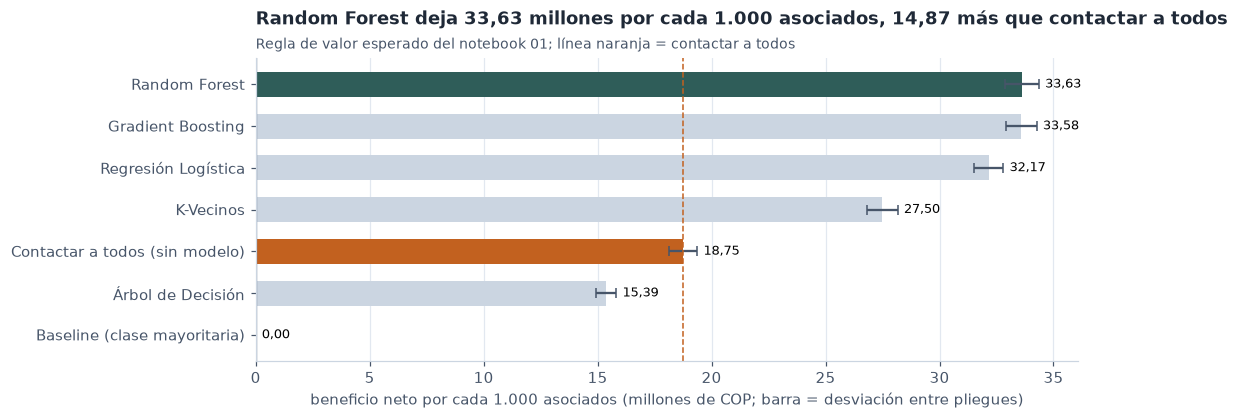

In [9]:
order_b = business.index[::-1]
fig, ax = plt.subplots(figsize=(10, 3.9))
colors = [CHURN if n.startswith("Contactar") else (NEUTRAL if n.startswith("Baseline") else
          (STAY if n == business.index[0] else LIGHT)) for n in order_b]
bars = ax.barh(order_b, business.loc[order_b, "beneficio neto (por 1.000)"],
               xerr=business.loc[order_b, "± beneficio"], color=colors, height=0.6,
               error_kw={"ecolor": SUBTEXT, "capsize": 3})
ax.bar_label(bars, labels=[fmt_num(v, 2) for v in business.loc[order_b, "beneficio neto (por 1.000)"]], padding=4, fontsize=8.5)
ax.axvline(mass.mean(), color=CHURN, ls="--", lw=1)
ax.axvline(0, color=SUBTEXT, lw=0.8)
ax.set_xlabel("beneficio neto por cada 1.000 asociados (millones de COP; barra = desviación entre pliegues)")
ax.grid(axis="y", visible=False)
top_b = business.index[0]
titled(ax, f"{top_b} deja {fmt_num(business.loc[top_b, 'beneficio neto (por 1.000)'], 2)} millones por cada 1.000 "
           f"asociados, {fmt_num(business.loc[top_b, 'frente a contactar a todos'], 2)} más que contactar a todos",
       "Regla de valor esperado del notebook 01; línea naranja = contactar a todos")
plt.tight_layout(); plt.show()

**Lectura en dinero.**

- **Cuatro de los cinco modelos superan a "contactar a todos"** (18,75 millones por cada 1.000 asociados en estos
  pliegues). Random Forest deja 33,63 y Gradient Boosting 33,58, unos 14,9 millones más por cada 1.000 asociados, con
  menos de la mitad de los contactos (406 y 404 por cada 1.000) y cubriendo cerca del 94 % del saldo de aportes en riesgo.
- **La Regresión Logística deja 32,17**: 1,46 millones menos que Random Forest por cada 1.000 asociados (7,2 veces el
  ruido, 5 de 5 pliegues). Es **el precio medido de elegir el modelo más explicable**.
- **El Árbol de Decisión queda por debajo de contactar a todos** (15,39): sus probabilidades de 0 o 1 hacen que la regla
  de valor esperado contacte solo a quien marca como seguro, y deja fuera más de la mitad del saldo en riesgo.
- **Por qué los modelos contactan a cerca del 40 %** si la tasa de radicación es del 21 %: la regla contacta a quien deja
  valor esperado positivo, y los asociados con mucho saldo valen la llamada aunque su probabilidad sea baja. Así se
  cubre casi todo el dinero en riesgo con menos de la mitad de los contactos.
- **Ojo con la calibración:** la regla usa la probabilidad como número. Random Forest tiene el mejor Brier (0,1005); aun
  así, la calibración se revisa en la validación final, junto con los supuestos de costo y efectividad.

**¿Cuánto aporta la regla de decisión?** Las dos últimas columnas comparan la regla de valor esperado con la regla
"de fábrica" (contactar a quien tenga probabilidad de 0,5 o más):

- **Con el umbral 0,5, ningún modelo supera a contactar a todos**: Random Forest dejaría 11,75 millones por cada 1.000
  asociados, frente a 18,75 de la campaña masiva. Contacta a muy pocos y deja pasar a los de saldo alto con probabilidad
  intermedia.
- **La regla de valor esperado le suma a cada modelo con probabilidades útiles** entre 16,57 (K-Vecinos) y 24,61
  (Regresión Logística) millones por cada 1.000 asociados: es lo que convierte al modelo en rentable.
- **Al Árbol de Decisión casi no le suma** (0,47), y al baseline nada: sin probabilidades útiles no hay nada que la regla
  pueda aprovechar.

Es el mismo hallazgo del ejemplo del curso (CreditSight): la regla de decisión de negocio mejora a todos los modelos que
tienen probabilidades útiles. **La métrica de negocio no solo se reporta: define cómo se decide.**

### A igual detección, ¿cuánto esfuerzo pide cada modelo?

El recall en el umbral 0,5 no compara modelos: compara puntos de operación de fábrica. Para comparar **capacidad**, se
fija la misma detección para todos: **el 75 % de quienes radican** (la regla de negocio del notebook del equipo). Con las
probabilidades fuera de pliegue se busca, para cada modelo, el umbral que la alcanza y se cuenta cuántos asociados hay
que contactar. **Esto no elige el umbral final** (eso es del notebook 07): solo traduce la diferencia de capacidad a
contactos.

In [10]:
from sklearn.metrics import precision_recall_curve

TARGET_RECALL = 0.75
effort = []
for name, p in oof.items():
    if name.startswith("Baseline"):
        continue
    # Se marca a todos los que superan un umbral: los empates (misma probabilidad) entran o salen juntos.
    _, recall_curve, thresholds = precision_recall_curve(y, p)
    threshold = thresholds[np.where(recall_curve[:-1] >= TARGET_RECALL)[0][-1]]
    flagged = p >= threshold
    effort.append({"modelo": name, "valores distintos de probabilidad": len(np.unique(p)),
                   "asociados a contactar": int(flagged.sum()), "% del total": flagged.mean(),
                   "recall alcanzado": y[flagged].sum() / y.sum(), "precisión": y[flagged].mean(),
                   "falsas alarmas": int(flagged.sum() - y[flagged].sum())})
effort = pd.DataFrame(effort).set_index("modelo").sort_values("asociados a contactar")
effort["contactos de más vs. el mejor"] = effort["asociados a contactar"] - effort["asociados a contactar"].min()
display(table(effort, decimals=4, pct_cols=["% del total", "recall alcanzado", "precisión"]))
print(f"Base: {fmt_num(len(y))} asociados de entrenamiento (probabilidades fuera de pliegue), "
      f"de los cuales {fmt_num(y.sum())} radicaron. Meta: detectar al menos {fmt_num(np.ceil(TARGET_RECALL * y.sum()))}.")
extra = effort.loc["Regresión Logística", "asociados a contactar"] - effort.loc["Random Forest", "asociados a contactar"]
print(f"La Regresión Logística necesita {fmt_num(extra)} contactos más que Random Forest para la misma meta: "
      f"${fmt_num(extra * CONTACT_COST, 1)} millones en contactos con el supuesto de ${fmt_num(CONTACT_COST * 1e6)} cada uno.")

,valores distintos de probabilidad,asociados a contactar,% del total,recall alcanzado,precisión,falsas alarmas,contactos de más vs. el mejor
modelo,,,,,,,
Random Forest,101,42.344,"27,3 %","75,5 %","57,9 %",17.812,0
Gradient Boosting,149.158,44.052,"28,4 %","75,0 %","55,3 %",19.697,1.708
Regresión Logística,155.233,57.380,"37,0 %","75,0 %","42,4 %",33.025,15.036
K-Vecinos,6,79.189,"51,0 %","86,1 %","35,3 %",51.232,36.845
Árbol de Decisión,2,155.258,"100,0 %","100,0 %","20,9 %",122.785,112.914


Base: 155.258 asociados de entrenamiento (probabilidades fuera de pliegue), de los cuales 32.473 radicaron. Meta: detectar al menos 24.355.
La Regresión Logística necesita 15.036 contactos más que Random Forest para la misma meta: $451,1 millones en contactos con el supuesto de $30.000 cada uno.


**Lectura.**

- **Para detectar al 75 % de quienes radican, Random Forest es el que menos contactos pide**, seguido de cerca por
  Gradient Boosting. **La Regresión Logística necesita unos 15.000 contactos más** (cifra exacta y su costo arriba): es el
  mismo patrón que encontró el notebook del equipo (4.605 frente a 2.210 falsas alarmas en su conjunto de validación).
- **K-Vecinos y el Árbol no pueden "parar" en el 75 %.** Sus probabilidades toman muy pocos valores (6 y 2): K-Vecinos
  salta al 86 % de recall contactando a la mitad de los asociados, y el árbol tiene que contactar a todos. Un modelo con
  probabilidades tan gruesas no permite elegir un punto de operación fino.
- **Nota de método:** los asociados con la misma probabilidad se marcan o se dejan **juntos**. Ordenarlos uno por uno
  sería un error: el conjunto de entrenamiento viene ordenado por grupo y el empate se resolvería por el orden de las
  filas, no por el modelo.

## 5. ¿Coinciden los rankings de negocio y técnico?

Posición de cada modelo (1 = mejor) en cada métrica. El baseline queda fuera: no compite.

In [11]:
ranks = pd.DataFrame({
    "AUC": summary.loc[contenders.index, "AUC"].rank(ascending=False),
    "PR-AUC": summary.loc[contenders.index, "PR-AUC"].rank(ascending=False),
    "beneficio neto": business.loc[contenders.index, "beneficio neto (por 1.000)"].rank(ascending=False),
    "esfuerzo a igual detección": effort.loc[contenders.index, "asociados a contactar"].rank(),
    "Brier": full.loc[contenders.index, "Brier"].rank(),
    "log loss": full.loc[contenders.index, "log loss"].rank(),
    "exactitud balanceada (0,5)": full.loc[contenders.index, "exactitud balanceada"].rank(ascending=False),
    "F1 macro (0,5)": full.loc[contenders.index, "F1 macro"].rank(ascending=False),
    "recall clase 1 (0,5)": full.loc[contenders.index, "recall"].rank(ascending=False),
    "F1 clase 1 (0,5)": full.loc[contenders.index, "F1"].rank(ascending=False),
}).rank(method="min").astype(int).sort_values("AUC")
display(ranks)

,AUC,PR-AUC,beneficio neto,esfuerzo a igual detección,Brier,log loss,"exactitud balanceada (0,5)","F1 macro (0,5)","recall clase 1 (0,5)","F1 clase 1 (0,5)"
Random Forest,1,1,1,1,1,1,1,1,2,1
Gradient Boosting,2,2,2,2,2,2,2,2,3,2
Regresión Logística,3,3,3,3,3,3,5,5,5,5
K-Vecinos,4,4,4,4,4,4,4,4,4,4
Árbol de Decisión,5,5,5,5,5,5,3,3,1,3


**Lectura.** **Los rankings coinciden** en todo lo que no depende del umbral de fábrica: AUC, PR-AUC, beneficio neto,
esfuerzo a igual detección, Brier y log loss ordenan igual (Random Forest, Gradient Boosting, Regresión Logística,
K-Vecinos y Árbol de Decisión).

Las que discrepan son las del umbral 0,5 (exactitud balanceada, F1 macro, recall y F1 de la clase 1): suben al árbol, que
dice "sí" con facilidad porque sus probabilidades son 0 o 1, y bajan a la logística al último lugar, porque sus
probabilidades rara vez pasan de 0,5. Random Forest y Gradient Boosting quedan arriba en casi todas. Por eso esas métricas
se leen siempre con su umbral al lado: en este torneo **ordenar bien y decidir bien coinciden** cuando se decide con la
regla de negocio, y la diferencia entre modelos es de capacidad, no de punto de operación.

## 6. ¿Y si las variables sospechosas fueran fuga?

El notebook 04 mostró que el modelo depende mucho de cuatro variables sospechosas. El equipo confirmó que no incluyen
el mes de radicación, pero falta aclarar por qué los porcentajes dividen por antigüedad + 1. Para saber **cuánto vale el
torneo en el peor caso**, se repite con los tres mejores **sin** esas variables (ni las nuevas que dependen de ellas).

In [12]:
safe_columns = [c for c in columns if c not in set(SUSPECT_COLUMNS) | set(SUSPECT_ENGINEERED)]
print(f"Sin sospechas: {len(safe_columns)} variables (de {len(columns)})")
models = candidates()
worst_case = []
for name in top:
    res = evaluate_folds(build_pipeline(models[name], safe_columns), train, folds)
    worst_case.append({"modelo": name, "AUC con todas": summary.loc[name, "AUC"], "AUC sin sospechas": res["AUC"].mean(),
                       "PR-AUC con todas": summary.loc[name, "PR-AUC"], "PR-AUC sin sospechas": res["PR-AUC"].mean(),
                       "± PR-AUC sin sospechas": res["PR-AUC"].std(),
                       "beneficio con todas": business.loc[name, "beneficio neto (por 1.000)"],
                       "beneficio sin sospechas": res["beneficio neto (por 1.000)"].mean()})
    print(f"{name:25s} listo")
worst_case = pd.DataFrame(worst_case).set_index("modelo")
display(table(worst_case, decimals=4, col_decimals={"beneficio con todas": 2, "beneficio sin sospechas": 2}))
print(f"Contactar a todos, en los mismos pliegues: {fmt_num(mass.mean(), 2)} millones por cada 1.000 asociados")

Sin sospechas: 22 variables (de 27)


Random Forest             listo


Gradient Boosting         listo


Regresión Logística       listo


,AUC con todas,AUC sin sospechas,PR-AUC con todas,PR-AUC sin sospechas,± PR-AUC sin sospechas,beneficio con todas,beneficio sin sospechas
modelo,,,,,,,
Random Forest,"0,8951","0,8401","0,7015","0,5946","0,0100","33,63","31,26"
Gradient Boosting,"0,8877","0,8304","0,6827","0,5743","0,0116","33,58","30,95"
Regresión Logística,"0,8189","0,7516","0,5145","0,4374","0,0064","32,17","29,66"


Contactar a todos, en los mismos pliegues: 18,75 millones por cada 1.000 asociados


**Lectura del peor caso.**

- **Sin las sospechas, todos pierden bastante**: el PR-AUC de Random Forest baja de 0,7015 a 0,5946 y su AUC de 0,8951 a
  0,8401; los otros dos caen en proporción parecida. Si esas variables resultaran ser fuga, este es el desempeño real.
- **Aun así, el modelo vale la pena**: el beneficio neto de Random Forest sin sospechas (31,26 millones por cada 1.000)
  sigue muy por encima de contactar a todos (18,75).
- **El orden no cambia**: Random Forest, Gradient Boosting y Regresión Logística, en ese orden, con y sin sospechas. La
  elección de finalistas no depende de esa duda.

## 7. Finalistas

| Finalista | Por qué | Qué podría cambiar con la optimización |
|---|---|---|
| **Random Forest** | Primero en AUC, PR-AUC, Brier, beneficio neto y esfuerzo; le gana a Gradient Boosting en los 5 pliegues en ordenamiento; entrena en menos de 20 s y predice rápido | Con profundidad, hojas mínimas y número de variables por árbol limitados, suele mejorar la calibración y reducir el tamaño del modelo para la app |
| **Gradient Boosting** | Segundo en todo y **empatado en beneficio neto** con Random Forest (0,8 veces el ruido); la familia de boosting es la que más suele ganar al ajustar hiperparámetros | Tasa de aprendizaje, número y profundidad de árboles; su versión histograma (`HistGradientBoostingClassifier`) entrena mucho más rápido |

**Descartados, y por qué:**

- **Regresión Logística.** Era la elección del equipo por explicable, auditable y liviana, y esas razones siguen siendo
  válidas. Pero el torneo mide su costo: 1,46 millones menos por cada 1.000 asociados que Random Forest y unos 15.000
  contactos más para la misma detección, siempre por muchas veces el ruido. **Es una decisión de negocio, no técnica**: si
  el comité exige coeficientes, se puede elegir la logística sabiendo cuánto cuesta. Si basta con explicar cada predicción,
  Random Forest con SHAP (etapa 7) da esa explicación sin pagar el costo. Se conserva como **referencia interpretable**.
- **K-Vecinos:** peor en todas las métricas, lento para predecir y con probabilidades tan gruesas que no permite elegir un
  punto de operación.
- **Árbol de Decisión:** con los parámetros por defecto memoriza el entrenamiento; queda por debajo de contactar a todos.

**Por qué el torneo no elige un campeón.** La diferencia entre Random Forest y Gradient Boosting es real en ordenamiento
pero desaparece en beneficio neto, y con hiperparámetros ajustados el orden puede cambiar. Además, nada de esto se ha
medido todavía en la prueba (que sigue cerrada), el umbral y la calibración no están elegidos, y los supuestos de costo y
efectividad están pendientes de confirmar. El campeón se elige después de optimizar (notebook 06) y se confirma una sola
vez con la prueba (notebook 07).

## Entregable de esta etapa

- [x] Seis candidatos (cinco modelos y una línea base), evaluados en **los mismos pliegues** y con las mismas variables.
- [x] Una fila **por pliegue** para cada modelo (`reports/05_torneo_pliegues.csv`) y las probabilidades fuera de pliegue
  (`data/processed/05_oof_probabilidades.joblib`).
- [x] Métricas técnicas (AUC, PR-AUC, recall, precisión, F1, Brier) y de negocio (beneficio neto, contactos, saldo cubierto).
- [x] Cada diferencia comparada con la variación entre pliegues; comparación pareada de los mejores.
- [x] La diferencia traducida a dinero y a contactos.
- [x] Finalistas justificados en `reports/05_torneo.md`.
- [x] Código reutilizable en `src/proyecto/models/`; este notebook solo lo llama.

**Siguiente:** `06_optimizacion.ipynb` (hiperparámetros de los finalistas, con seguimiento en MLflow).